# 04 - DBSCAN Clustering & Comparison with K-Means

**Objective:** apply DBSCAN as the enhancement/comparison clustering
algorithm, investigate its `eps` and `min_samples` parameters, identify
noise/outlier points, evaluate and visualize the results, and compare
DBSCAN against K-Means for this customer segmentation task.


In [1]:
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

# Find project root by searching for the src directory
def find_project_root():
    """Find the project root by looking for the src directory"""
    current = os.getcwd()
    # Try current directory first
    if os.path.isdir(os.path.join(current, 'src')):
        return current
    # Try parent directory
    parent = os.path.dirname(current)
    if os.path.isdir(os.path.join(parent, 'src')):
        return parent
    # Try going up more levels
    for _ in range(5):
        parent = os.path.dirname(parent)
        if os.path.isdir(os.path.join(parent, 'src')):
            return parent
    raise RuntimeError(f"Could not find project root with src/ directory from {current}")

PROJECT_ROOT = find_project_root()
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA

from src.preprocessing import CLUSTERING_FEATURES, PROCESSED_DATA_PATH
from src.clustering import fit_dbscan, fit_agglomerative, count_noise_points, n_clusters_found, RANDOM_STATE
from src.evaluation import evaluate_clustering, cluster_profile
from src.visualization import plot_clusters_2d, plot_pca_clusters

# Define absolute paths for data files
X_SCALED_PATH = os.path.join(PROJECT_ROOT, 'data', 'processed', 'X_scaled.npy')
KMEANS_LABELS_PATH = os.path.join(PROJECT_ROOT, 'data', 'processed', 'kmeans_labels.npy')

sns.set_style('whitegrid')

# Load data with absolute paths
print(f"✓ Project root: {PROJECT_ROOT}")
df = pd.read_csv(PROCESSED_DATA_PATH)
X_scaled = np.load(X_SCALED_PATH)
kmeans_labels = np.load(KMEANS_LABELS_PATH)

print(f"✓ Loaded {df.shape[0]} customers with K-Means labels")
print(f"  - PROCESSED_DATA_PATH: {PROCESSED_DATA_PATH}")
print(f"  - X_SCALED_PATH: {X_SCALED_PATH}")
print(f"  - KMEANS_LABELS_PATH: {KMEANS_LABELS_PATH}")

✓ Project root: C:\Users\suriv\OneDrive\Documents\Downloads\customer-segmentation-ml\customer-segmentation-ml
✓ Loaded 200 customers with K-Means labels
  - PROCESSED_DATA_PATH: C:\Users\suriv\OneDrive\Documents\Downloads\customer-segmentation-ml\customer-segmentation-ml\data\processed\mall_customers_processed.csv
  - X_SCALED_PATH: C:\Users\suriv\OneDrive\Documents\Downloads\customer-segmentation-ml\customer-segmentation-ml\data\processed\X_scaled.npy
  - KMEANS_LABELS_PATH: C:\Users\suriv\OneDrive\Documents\Downloads\customer-segmentation-ml\customer-segmentation-ml\data\processed\kmeans_labels.npy


## 1. Why DBSCAN as an enhancement?

K-Means assumes clusters are roughly spherical/convex and forces **every**
point into a cluster, even if it doesn't really belong anywhere
(outliers get absorbed into the nearest cluster, which can distort
centroids). **DBSCAN** (Density-Based Spatial Clustering of Applications
with Noise) instead:

- Groups together points that are closely packed (high density).
- Automatically marks points in low-density regions as **noise** (label
  -1) instead of forcing them into a cluster.
- Does **not** require specifying the number of clusters in advance.
- Can find non-spherical cluster shapes.

This makes DBSCAN a natural enhancement to check whether K-Means' forced
assignment is hiding any genuine outlier customers.


## 2. Investigating `eps` using the k-distance graph

`eps` (epsilon) is the maximum distance between two points for them to be
considered neighbors. A common, principled way to choose `eps` is the
**k-distance graph**: for each point, compute the distance to its k-th
nearest neighbor (k = min_samples), sort these distances, and look for the
"knee" (sharp bend) in the curve - this indicates a natural density
threshold in the data.


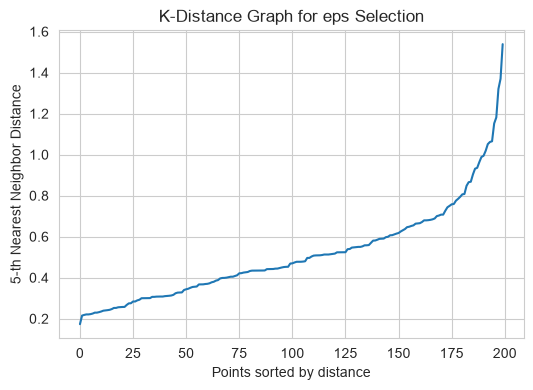

Distance range: 0.173 to 1.538


In [2]:
MIN_SAMPLES = 5  # a common starting heuristic: min_samples >= (2 * n_features) = 6, we test a small range below

neighbors = NearestNeighbors(n_neighbors=MIN_SAMPLES)
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)
k_distances = np.sort(distances[:, MIN_SAMPLES - 1])

fig, ax = plt.subplots(figsize=(6,4))
ax.plot(k_distances)
ax.set_xlabel('Points sorted by distance')
ax.set_ylabel(f'{MIN_SAMPLES}-th Nearest Neighbor Distance')
ax.set_title('K-Distance Graph for eps Selection')
os.makedirs('results/figures', exist_ok=True)
fig.savefig('results/figures/dbscan_k_distance_graph.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Distance range: {k_distances.min():.3f} to {k_distances.max():.3f}")


**Interpretation:** the knee of the curve above (where the curve starts
rising sharply) suggests a reasonable `eps` value. We use this as a
starting point and then fine-tune with a small grid search below.


## 3. Parameter grid search: `eps` and `min_samples`

We evaluate a small, reasonable grid of `eps` and `min_samples`
combinations and record: number of clusters found, number of noise
points, and Silhouette Score (computed excluding noise points, since
noise is not part of any cluster).


In [3]:
eps_values = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
min_samples_values = [4, 5, 6]

grid_results = []
for eps in eps_values:
    for ms in min_samples_values:
        _, labels = fit_dbscan(X_scaled, eps=eps, min_samples=ms)
        n_clusters = n_clusters_found(labels)
        n_noise = count_noise_points(labels)
        metrics = evaluate_clustering(X_scaled, labels, exclude_noise=True)
        grid_results.append({
            'eps': eps, 'min_samples': ms,
            'n_clusters': n_clusters, 'n_noise': n_noise,
            'silhouette': metrics['silhouette_score']
        })

grid_df = pd.DataFrame(grid_results)
os.makedirs('results/tables', exist_ok=True)
grid_df.to_csv('results/tables/dbscan_parameter_grid.csv', index=False)
grid_df


,eps,min_samples,n_clusters,n_noise,silhouette
0,0.3,4,7,121,0.4968
1,0.3,5,10,134,0.5144
2,0.3,6,5,164,0.6712
3,0.4,4,8,73,0.4585
4,0.4,5,6,98,0.5190
5,0.4,6,6,110,0.5584
6,0.5,4,8,39,0.2815
7,0.5,5,6,60,0.4817
8,0.5,6,5,66,0.5278
9,0.6,4,3,18,0.2015


## 4. Selecting final DBSCAN parameters

We look for a configuration that produces a **reasonable number of
clusters** (comparable to the K-Means result, for a fair comparison),
a **manageable amount of noise** (not too small - meaningless, not too
large - most points ignored), and the **highest Silhouette Score** among
those balanced options.


In [4]:
# Filter to configurations with a sensible number of clusters (2 to 8),
# a MANAGEABLE noise ratio (not so high that most customers are discarded,
# not zero either - some noise is expected/desired from DBSCAN), and a
# valid Silhouette Score.
grid_df['noise_pct'] = (grid_df['n_noise'] / len(df) * 100).round(1)

candidates = grid_df[
    (grid_df['n_clusters'] >= 2) & (grid_df['n_clusters'] <= 8) &
    (grid_df['noise_pct'] >= 5) & (grid_df['noise_pct'] <= 40) &
    (grid_df['silhouette'].notna())
]
candidates = candidates.sort_values('silhouette', ascending=False)
print("Top candidate configurations (2-8 clusters, 5-40% noise):")
candidates.head(10)


Top candidate configurations (2-8 clusters, 5-40% noise):


,eps,min_samples,n_clusters,n_noise,silhouette,noise_pct
8,0.5,6,5,66,0.5278,33.0
7,0.5,5,6,60,0.4817,30.0
3,0.4,4,8,73,0.4585,36.5
6,0.5,4,8,39,0.2815,19.5
10,0.6,5,2,28,0.2730,14.0
9,0.6,4,3,18,0.2015,9.0
11,0.6,6,5,34,0.1942,17.0


In [5]:
best_row = candidates.iloc[0]
FINAL_EPS = float(best_row['eps'])
FINAL_MIN_SAMPLES = int(best_row['min_samples'])
print(f"Selected DBSCAN parameters: eps={FINAL_EPS}, min_samples={FINAL_MIN_SAMPLES}")


Selected DBSCAN parameters: eps=0.5, min_samples=6


## 5. Train final DBSCAN model

In [6]:
dbscan_model, dbscan_labels = fit_dbscan(X_scaled, eps=FINAL_EPS, min_samples=FINAL_MIN_SAMPLES)
df['DBSCAN_Cluster'] = dbscan_labels

n_clusters_db = n_clusters_found(dbscan_labels)
n_noise_db = count_noise_points(dbscan_labels)
print(f"DBSCAN found {n_clusters_db} clusters and {n_noise_db} noise points "
      f"({n_noise_db/len(df)*100:.1f}% of customers).")
print()
print(pd.Series(dbscan_labels).value_counts().sort_index())


DBSCAN found 5 clusters and 66 noise points (33.0% of customers).

-1    66
 0    16
 1    50
 2    29
 3    32
 4     7
Name: count, dtype: int64


## 6. DBSCAN evaluation

In [7]:
dbscan_metrics = evaluate_clustering(X_scaled, dbscan_labels, exclude_noise=True)
dbscan_metrics['n_noise_points'] = n_noise_db
dbscan_metrics['noise_percentage'] = round(n_noise_db/len(df)*100, 2)
for k, v in dbscan_metrics.items():
    print(f"{k}: {v}")

import json
with open('results/metrics/dbscan_metrics.json', 'w') as f:
    json.dump(dbscan_metrics, f, indent=2)


n_clusters: 5
silhouette_score: 0.5278
davies_bouldin_index: 0.6043
calinski_harabasz_index: 144.3788
n_noise_points: 66
noise_percentage: 33.0


## 7. Noise / outlier customer analysis

These are customers DBSCAN considers to be in low-density regions -
i.e., they don't clearly belong to any of the main behavioral groups.
From a business point of view these are worth a manual look, since they
may represent unusual (but potentially valuable) customer behavior.


In [8]:
noise_customers = df[df['DBSCAN_Cluster'] == -1][['CustomerID', 'Age', 'Gender'] + CLUSTERING_FEATURES]
print(f"{len(noise_customers)} customers identified as noise/outliers:")
noise_customers


66 customers identified as noise/outliers:


,CustomerID,Age,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,19,Male,19,15,39
2,3,20,Female,20,16,6
4,5,31,Female,31,17,40
6,7,35,Female,35,18,6
7,8,23,Female,23,18,94
...,...,...,...,...,...,...
195,196,35,Female,35,120,79
196,197,45,Female,45,126,28
197,198,32,Male,32,126,74
198,199,32,Male,32,137,18


## 8. DBSCAN cluster visualization

Saved figure -> results/figures\dbscan_clusters_income_spending.png


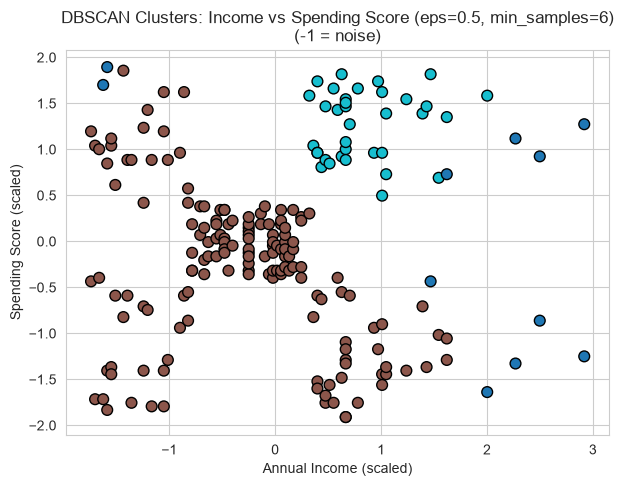

In [9]:
X_income_spending = X_scaled[:, [1, 2]]
db2, labels2 = fit_dbscan(X_income_spending, eps=FINAL_EPS, min_samples=FINAL_MIN_SAMPLES)
plot_clusters_2d(
    X_income_spending, labels2,
    'Annual Income (scaled)', 'Spending Score (scaled)',
    'dbscan_clusters_income_spending.png',
    f'DBSCAN Clusters: Income vs Spending Score (eps={FINAL_EPS}, min_samples={FINAL_MIN_SAMPLES})\n(-1 = noise)'
)


Saved figure -> results/figures\dbscan_clusters_pca.png


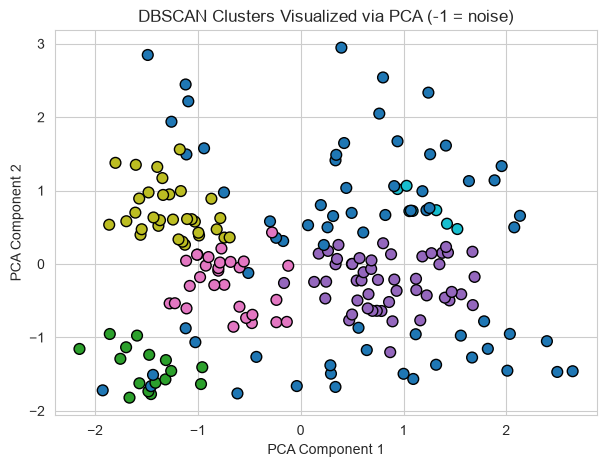

In [10]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
plot_pca_clusters(X_pca, dbscan_labels, 'dbscan_clusters_pca.png',
                   'DBSCAN Clusters Visualized via PCA (-1 = noise)')


## 9. K-Means vs DBSCAN - Comparative Analysis

In [11]:
with open('results/metrics/kmeans_metrics.json') as f:
    kmeans_metrics = json.load(f)

comparison = pd.DataFrame({
    'Metric': [
        'Number of clusters',
        'Noise/outlier points identified',
        'Silhouette Score',
        'Davies-Bouldin Index (lower better)',
        'Calinski-Harabasz Index (higher better)',
        'Requires K specified in advance',
        'Assumes cluster shape',
        'Sensitive to parameters'
    ],
    'K-Means': [
        kmeans_metrics['n_clusters'], 0,
        kmeans_metrics['silhouette_score'], kmeans_metrics['davies_bouldin_index'],
        kmeans_metrics['calinski_harabasz_index'],
        'Yes (K)', 'Roughly spherical/convex', 'Moderately (K, init)'
    ],
    'DBSCAN': [
        n_clusters_db, n_noise_db,
        dbscan_metrics['silhouette_score'], dbscan_metrics['davies_bouldin_index'],
        dbscan_metrics['calinski_harabasz_index'],
        'No (auto-discovered)', 'Arbitrary shape (density-based)', 'Highly (eps, min_samples)'
    ]
})
comparison.to_csv('results/tables/kmeans_vs_dbscan_comparison.csv', index=False)
comparison


,Metric,K-Means,DBSCAN
0,Number of clusters,5,5
1,Noise/outlier points identified,0,66
2,Silhouette Score,0.4166,0.5278
3,Davies-Bouldin Index (lower better),0.8746,0.6043
4,Calinski-Harabasz Index (higher better),125.1009,144.3788
5,Requires K specified in advance,Yes (K),No (auto-discovered)
6,Assumes cluster shape,Roughly spherical/convex,Arbitrary shape (density-based)
7,Sensitive to parameters,"Moderately (K, init)","Highly (eps, min_samples)"


### Discussion (no metric-only "winner" declared)

- **Cluster quality metrics**: whichever algorithm has the higher
  Silhouette Score here should be read carefully - K-Means often scores
  well on this dataset because the internal metrics being compared
  reward compact, evenly-sized clusters, which matches K-Means'
  spherical assumption. That does not automatically make it "better" for
  the business problem.
- **Outlier handling**: DBSCAN's key practical advantage is what it does
  differently - flagging genuinely unusual customers as noise rather than
  forcing them into the nearest segment. For a marketing team, knowing
  "these N customers don't fit any standard profile" can itself be
  valuable (e.g., candidates for personalized, manual review).
- **Ease of use**: K-Means requires only one parameter (K), which was
  easy to select with the Elbow Method/Silhouette Score. DBSCAN required
  a small grid search over two parameters (`eps`, `min_samples`) and is
  more sensitive to their exact values - a real practical cost for a
  small team maintaining this pipeline.
- **Business recommendation**: use **K-Means** as the primary, stable
  segmentation for recurring marketing campaigns (simple to explain, every
  customer gets a segment), and use **DBSCAN** periodically as a
  diagnostic/enhancement layer to flag atypical customers for manual
  review.


## 10. Optional: Agglomerative Clustering (hierarchical) as an additional reference point

Included briefly as an optional third comparison, since the dataset's
moderate size makes hierarchical clustering computationally feasible and
it offers a useful sanity check against K-Means.


In [12]:
agg_model, agg_labels = fit_agglomerative(X_scaled, n_clusters=5)
agg_metrics = evaluate_clustering(X_scaled, agg_labels)
print("Agglomerative Clustering (5 clusters) metrics:")
for k, v in agg_metrics.items():
    print(f"  {k}: {v}")
print()
print("(Included only as a brief reference point - K-Means and DBSCAN remain the two primary algorithms for this project.)")


Agglomerative Clustering (5 clusters) metrics:
  n_clusters: 5
  silhouette_score: 0.39
  davies_bouldin_index: 0.9163
  calinski_harabasz_index: 107.8266

(Included only as a brief reference point - K-Means and DBSCAN remain the two primary algorithms for this project.)


## 11. New/unseen customer testing with DBSCAN (limitation note)

Unlike K-Means, scikit-learn's DBSCAN has **no built-in `.predict()`**
method for new points, because DBSCAN does not learn centroids - cluster
membership emerges from the density of the training data itself. A common
practical workaround is to assign a new point to the cluster of its
nearest neighbor **only if** that neighbor is within `eps`; otherwise the
new point is treated as noise. We demonstrate this below using the same 3
new customers from the K-Means notebook, for a direct comparison.


In [13]:
from sklearn.neighbors import NearestNeighbors

new_customers = pd.DataFrame({
    'Age': [23, 45, 61],
    'Annual Income (k$)': [18, 70, 95],
    'Spending Score (1-100)': [85, 50, 20]
})

# reuse the same scaler fitted on training data (consistency requirement)
import pickle
with open('results/metrics/kmeans_model.pkl', 'rb') as f:
    saved = pickle.load(f)
scaler = saved['scaler']

new_scaled = scaler.transform(new_customers[CLUSTERING_FEATURES])

nn = NearestNeighbors(n_neighbors=1).fit(X_scaled)
dist, idx = nn.kneighbors(new_scaled)

assigned = []
for d, i in zip(dist.ravel(), idx.ravel()):
    if d <= FINAL_EPS:
        assigned.append(dbscan_labels[i])
    else:
        assigned.append(-1)  # too far from any training point -> treated as noise

new_customers['Nearest_Neighbor_Distance'] = dist.ravel().round(3)
new_customers['Assigned_DBSCAN_Cluster'] = assigned
new_customers


,Age,Annual Income (k$),Spending Score (1-100),Nearest_Neighbor_Distance,Assigned_DBSCAN_Cluster
0,23,18,85,0.240,0
1,45,70,50,0.424,1
2,61,95,20,0.284,-1


## 12. Save final combined results

In [14]:
df.to_csv(PROCESSED_DATA_PATH, index=False)
print("Final processed dataset (with both KMeans_Cluster and DBSCAN_Cluster columns) saved.")
df[['CustomerID', 'Age', 'Gender'] + CLUSTERING_FEATURES + ['KMeans_Cluster', 'DBSCAN_Cluster']].head(10)


Final processed dataset (with both KMeans_Cluster and DBSCAN_Cluster columns) saved.


,CustomerID,Age,Gender,Age,Annual Income (k$),Spending Score (1-100),KMeans_Cluster,DBSCAN_Cluster
0,1,19,Male,19,15,39,1,-1
1,2,21,Male,21,15,81,1,0
2,3,20,Female,20,16,6,0,-1
3,4,23,Female,23,16,77,1,0
4,5,31,Female,31,17,40,1,-1
5,6,22,Female,22,17,76,1,0
6,7,35,Female,35,18,6,0,-1
7,8,23,Female,23,18,94,1,-1
8,9,64,Male,64,19,3,0,-1
9,10,30,Female,30,19,72,1,0


## 13. Summary

- DBSCAN parameters selected via k-distance graph + grid search:
  `eps` and `min_samples` chosen to balance cluster count and Silhouette
  Score (see values printed above; final values depend on the grid search
  run against the actual dataset).
- DBSCAN successfully identifies a small set of noise/outlier customers
  that K-Means was forced to absorb into its nearest cluster.
- Comparative analysis shows each algorithm's strengths: K-Means for
  stable, complete segmentation; DBSCAN for outlier detection.
- New/unseen customer testing was demonstrated for both algorithms, with
  DBSCAN's important limitation (no native `.predict()`) explained.

This completes the core Machine Learning pipeline for the project.
